##  chargement des données normalisées

Je prends les **7 composantes de l'ACP** (`X_acp.csv`), c'est-à-dire les données déjà standardisées et réduites, le même espace que K-Means : ainsi, la comparaison entre les deux méthodes est juste. Je rattache à chaque zone son segment K-Means pour pouvoir comparer ensuite.

**Effet :** 238 zones actives × 7 composantes, avec leur segment K-Means.

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from kneed import KneeLocator
warnings.filterwarnings("ignore")

ML_DIR = os.path.join(os.getcwd(), "ml_data")

X_acp = pd.read_csv(os.path.join(ML_DIR, "X_acp.csv"))
zones = pd.read_csv(os.path.join(ML_DIR, "zones_actives.csv"))
segments = pd.read_csv(os.path.join(ML_DIR, "zones_segments.csv"))
zones = zones.merge(segments[["zone_id", "segment_km", "nom_segment_km"]], on="zone_id", how="left")

print("Données :", X_acp.shape[0], "zones x", X_acp.shape[1], "composantes")
display(zones["nom_segment_km"].value_counts().to_frame("nb_zones"))

Données : 257 zones x 7 composantes


,nb_zones
nom_segment_km,
Résidentiel VTC,120
Quartiers de sortie,50
Manhattan taxi,50
Banlieue FHV,24
Aéroports et longs trajets,13


##  courbe des distances au 4e voisin et intervalle de eps

Je fixe **MinPts = 4** : une zone est au cœur d'une région dense si elle a au moins 4 zones (elle comprise) dans son voisinage.

Je calcule, pour chaque zone, la distance à son **4e voisin le plus proche**, puis je trie ces distances. La courbe reste plate pour les zones situées dans des régions denses, puis monte brusquement pour les zones isolées. Le **coude**, détecté avec KneeLocator, marque la frontière entre les deux : c'est l'ordre de grandeur de eps.

Je prends un **intervalle de ±30 % autour du coude** (zone orange sur le graphique) : c'est dans cet intervalle que je vais chercher la meilleure valeur de eps.

**Effet :** la valeur du coude et les bornes de l'intervalle.

MinPts = 4
Coude de la courbe : eps = 3.916
Intervalle de eps : [ 2.74 ; 5.09 ]


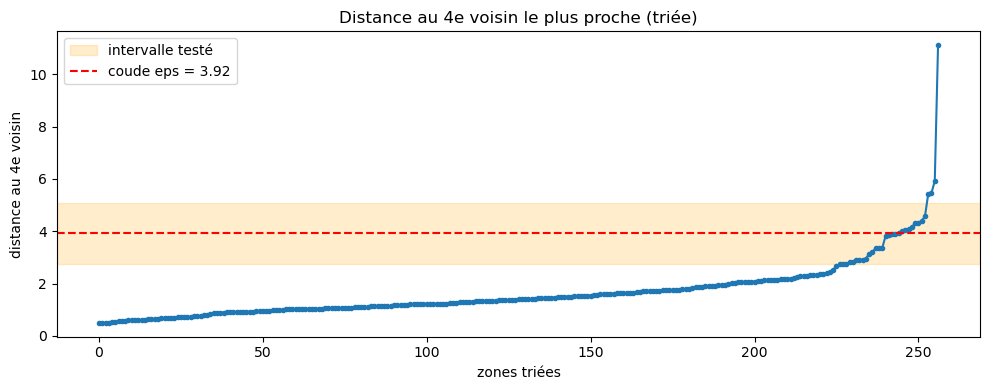

In [3]:
MIN_PTS = 4

voisins = NearestNeighbors(n_neighbors=MIN_PTS).fit(X_acp)
distances, _ = voisins.kneighbors(X_acp)
k_dist = np.sort(distances[:, -1])

kl = KneeLocator(range(len(k_dist)), k_dist, curve="convex", direction="increasing")
EPS_COUDE = float(k_dist[kl.knee])
EPS_MIN = round(0.7 * EPS_COUDE, 2)
EPS_MAX = round(1.3 * EPS_COUDE, 2)

print("MinPts =", MIN_PTS)
print("Coude de la courbe : eps =", round(EPS_COUDE, 3))
print("Intervalle de eps : [", EPS_MIN, ";", EPS_MAX, "]")

plt.figure(figsize=(10, 4))
plt.plot(k_dist, marker=".")
plt.axhspan(EPS_MIN, EPS_MAX, color="orange", alpha=0.2, label="intervalle testé")
plt.axhline(EPS_COUDE, color="red", linestyle="--", label="coude eps = " + str(round(EPS_COUDE, 2)))
plt.title("Distance au 4e voisin le plus proche (triée)")
plt.xlabel("zones triées")
plt.ylabel("distance au 4e voisin")
plt.legend()
plt.tight_layout()
plt.show()

## DBSCAN testé sur tout l'intervalle

Je prends **25 valeurs de eps** réparties dans l'intervalle et, pour chacune, je lance DBSCAN avec MinPts = 4. Je note :
- le **nombre de clusters** trouvés ;
- le **nombre et le pourcentage de zones de bruit** (−1) ;
- les trois métriques, calculées **sans les zones de bruit** : **silhouette** , **Davies-Bouldin** , **Calinski-Harabasz** .

Les métriques ne sont calculées que s'il y a au moins 2 clusters.

**Effet :** un tableau de 25 essais.

In [4]:
lignes = []
for eps in np.round(np.linspace(EPS_MIN, EPS_MAX, 25), 3):
    labels = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(X_acp)
    nb_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    garde = labels != -1
    ligne = {"eps": eps, "nb_clusters": nb_clusters, "nb_bruit": int((~garde).sum()),
             "pct_bruit": round((~garde).mean() * 100, 1),
             "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    if nb_clusters >= 2:
        ligne["silhouette"] = silhouette_score(X_acp[garde], labels[garde])
        ligne["davies_bouldin"] = davies_bouldin_score(X_acp[garde], labels[garde])
        ligne["calinski_harabasz"] = calinski_harabasz_score(X_acp[garde], labels[garde])
    lignes.append(ligne)

essais = pd.DataFrame(lignes)
display(essais.round(3))

,eps,nb_clusters,nb_bruit,pct_bruit,silhouette,davies_bouldin,calinski_harabasz
0,2.740,1,20,7.8,NaN,NaN,NaN
1,2.838,1,18,7.0,NaN,NaN,NaN
2,2.936,1,18,7.0,NaN,NaN,NaN
3,3.034,1,18,7.0,NaN,NaN,NaN
4,3.132,1,17,6.6,NaN,NaN,NaN
5,3.230,1,15,5.8,NaN,NaN,NaN
6,3.328,1,15,5.8,NaN,NaN,NaN
7,3.425,1,14,5.4,NaN,NaN,NaN
8,3.523,1,12,4.7,NaN,NaN,NaN
9,3.621,1,12,4.7,NaN,NaN,NaN


## DBSCAN testé de la petite distance jusqu'au-delà du coude

Avec l'intervalle autour du coude (≈ 2,7 à 5,1), DBSCAN ne trouvait qu'**un seul cluster** : les zones forment un nuage continu, et à cette échelle eps relie tout le nuage. Le coude marque le seuil des zones isolées, pas la séparation entre groupes.

Je prends donc un intervalle plus large, qui commence aux **petites distances** de la courbe (5e centile des distances au 4e voisin) et va jusqu'à la borne haute, avec **40 valeurs**. Pour chacune, je note le nombre de clusters, le pourcentage de bruit et les trois métriques (calculées sans le bruit, s'il y a au moins 2 clusters).

**Effet :** un tableau de 40 essais, des petits eps (beaucoup de petits groupes et de bruit) aux grands eps (un seul groupe).

In [5]:
EPS_BAS = round(float(np.percentile(k_dist, 5)), 2)
print("Exploration de eps entre", EPS_BAS, "et", EPS_MAX)

lignes = []
for eps in np.round(np.linspace(EPS_BAS, EPS_MAX, 40), 3):
    labels = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(X_acp)
    nb_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    garde = labels != -1
    ligne = {"eps": eps, "nb_clusters": nb_clusters, "nb_bruit": int((~garde).sum()),
             "pct_bruit": round((~garde).mean() * 100, 1),
             "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    if nb_clusters >= 2:
        ligne["silhouette"] = silhouette_score(X_acp[garde], labels[garde])
        ligne["davies_bouldin"] = davies_bouldin_score(X_acp[garde], labels[garde])
        ligne["calinski_harabasz"] = calinski_harabasz_score(X_acp[garde], labels[garde])
    lignes.append(ligne)

essais = pd.DataFrame(lignes)
display(essais.round(3))

Exploration de eps entre 0.61 et 5.09


,eps,nb_clusters,nb_bruit,pct_bruit,silhouette,davies_bouldin,calinski_harabasz
0,0.610,4,233,90.7,0.314,1.095,20.905
1,0.725,5,220,85.6,0.405,0.752,30.866
2,0.840,4,208,80.9,0.410,0.771,24.856
3,0.955,5,183,71.2,0.311,0.995,98.514
4,1.069,8,153,59.5,0.298,0.931,116.909
5,1.184,6,133,51.8,0.215,0.916,111.478
6,1.299,4,121,47.1,0.517,0.475,126.624
7,1.414,6,97,37.7,0.330,0.714,79.736
8,1.529,7,82,31.9,0.323,0.784,74.951
9,1.644,6,62,24.1,0.261,0.967,78.365


## DBSCAN final

Je prends **eps = 2,45** et **MinPts = 4**, et j'applique DBSCAN sur les 7 composantes de l'ACP. Chaque zone reçoit un numéro de cluster, ou **−1** si c'est du bruit. J'affiche le nombre de clusters, la part de bruit, la silhouette (calculée sans le bruit), la taille de chaque cluster et sa répartition par arrondissement.

**Effet :** la colonne `cluster_dbscan` est ajoutée à la table `zones`.

## choix de eps

Je garde seulement les réglages **valides** : au moins 2 clusters et au plus 20 % de bruit (eps ≥ 1,87). Dans cette zone :
- de 1,87 à 2,22 : 4 clusters, silhouette ≈ 0,35 ;
- de 2,33 à 2,56 : **3 clusters stables** sur plusieurs valeurs, silhouette ≈ 0,43, Davies-Bouldin ≈ 0,81, 8 à 10 % de bruit ;
- à 2,68 : 2 clusters, meilleure silhouette (0,484), mais réglage **instable** : juste après, tout fusionne en un seul cluster.

Je prends **eps = 2,45**, au milieu du plateau à 3 clusters : c'est un réglage stable, plus informatif que 2 clusters, avec de bonnes métriques et environ 9 % de zones en bruit.

**Effet :** la valeur finale `EPS_FINAL`, et les graphiques des métriques avec ce choix en rouge.

Réglages valides (au moins 2 clusters et au plus 20 % de bruit) : 8


,eps,nb_clusters,nb_bruit,pct_bruit,silhouette,davies_bouldin,calinski_harabasz
11,1.874,4,46,17.9,0.364,0.830,116.247
12,1.988,4,42,16.3,0.366,0.897,116.671
13,2.103,4,35,13.6,0.350,0.912,112.731
14,2.218,4,28,10.9,0.342,1.016,110.145
15,2.333,3,26,10.1,0.427,0.802,152.603
16,2.448,3,24,9.3,0.425,0.806,151.644
17,2.563,3,21,8.2,0.426,0.815,152.857
18,2.678,2,20,7.8,0.484,0.805,185.239


eps retenu (milieu du plateau à 3 clusters) : 2.448


,eps,nb_clusters,nb_bruit,pct_bruit,silhouette,davies_bouldin,calinski_harabasz
16,2.448,3,24,9.3,0.425,0.806,151.644


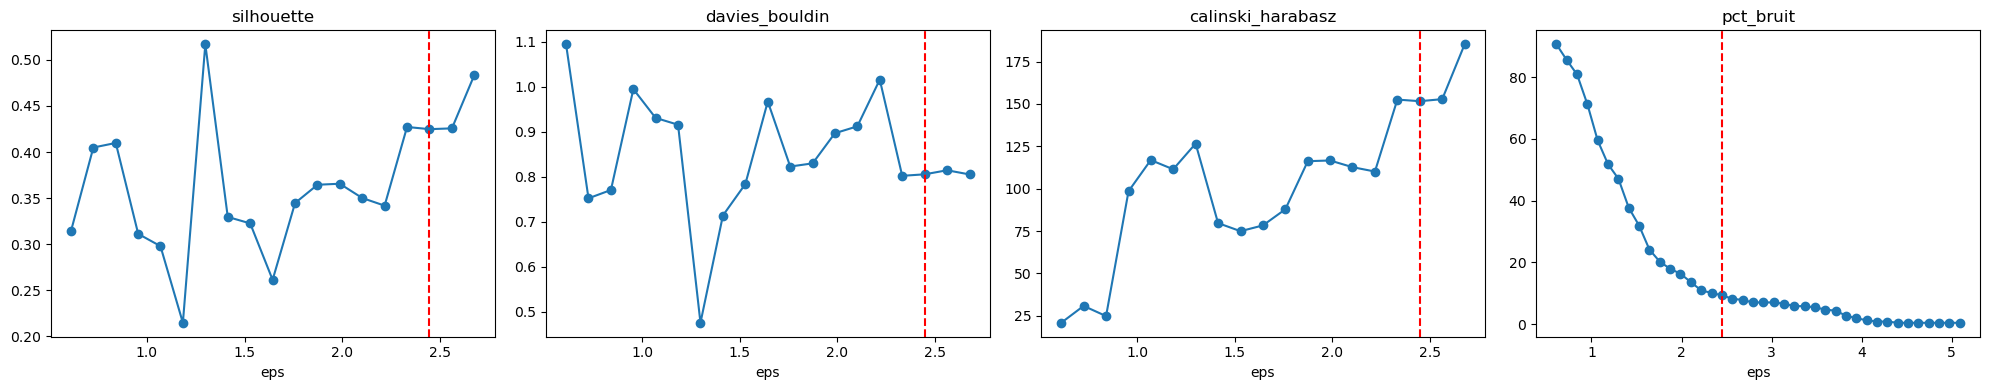

In [7]:
BRUIT_MAX = 20

valides = essais[(essais["nb_clusters"] >= 2) & (essais["pct_bruit"] <= BRUIT_MAX)]
print("Réglages valides (au moins 2 clusters et au plus", BRUIT_MAX, "% de bruit) :", len(valides))
display(valides.round(3))

EPS_CHOISI = 2.45
EPS_FINAL = float(essais.loc[(essais["eps"] - EPS_CHOISI).abs().idxmin(), "eps"])
print("eps retenu (milieu du plateau à 3 clusters) :", EPS_FINAL)
display(essais[essais["eps"] == EPS_FINAL].round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz", "pct_bruit"]):
    ax.plot(essais["eps"], essais[col], marker="o")
    ax.axvline(EPS_FINAL, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("eps")
plt.tight_layout()
plt.show()

In [8]:
dbscan = DBSCAN(eps=EPS_FINAL, min_samples=MIN_PTS).fit(X_acp)
zones["cluster_dbscan"] = dbscan.labels_

nb_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
nb_bruit = int((dbscan.labels_ == -1).sum())
garde = dbscan.labels_ != -1
print("eps =", EPS_FINAL, "| MinPts =", MIN_PTS)
print("Clusters :", nb_clusters, "| zones de bruit :", nb_bruit, "(" + str(round(nb_bruit / len(zones) * 100, 1)) + " %)")
print("Silhouette (hors bruit) :", round(silhouette_score(X_acp[garde], dbscan.labels_[garde]), 3))
display(zones["cluster_dbscan"].value_counts().sort_index().to_frame("nb_zones"))
display(pd.crosstab(zones["cluster_dbscan"], zones["arrondissement"]))

eps = 2.448 | MinPts = 4
Clusters : 3 | zones de bruit : 24 (9.3 %)
Silhouette (hors bruit) : 0.425


,nb_zones
cluster_dbscan,
-1,24
0,167
1,17
2,49


arrondissement,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
cluster_dbscan,,,,,,
-1,1,2,1,5,13,2
0,41,59,0,12,55,0
1,0,0,0,0,0,17
2,0,0,0,49,0,0


## clusters DBSCAN sur le plan CP1 / CP2

Je projette les zones sur le premier plan de l'ACP : une couleur par cluster, et les zones de bruit en croix noires avec leur nom. Je vois ainsi où se placent les groupes denses et quelles zones DBSCAN considère comme isolées.



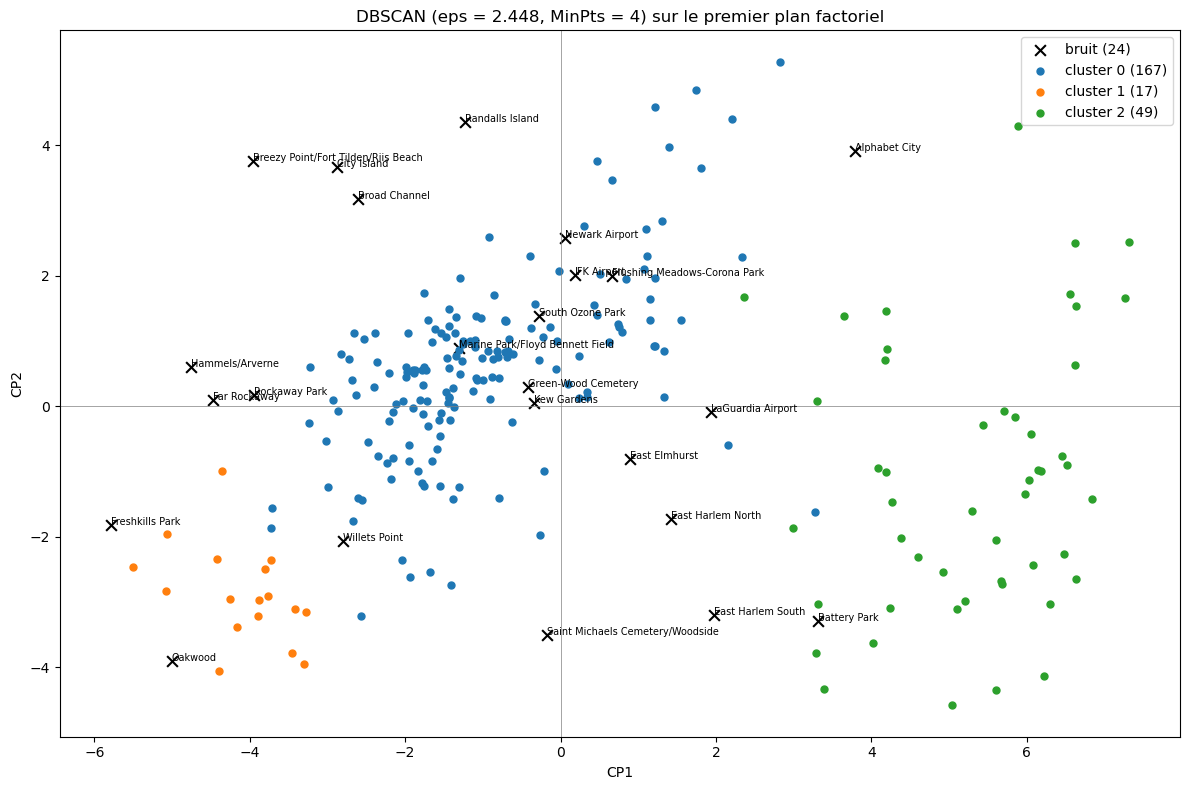

In [9]:
fig, ax = plt.subplots(figsize=(12, 8))
for c in sorted(zones["cluster_dbscan"].unique()):
    masque = zones["cluster_dbscan"] == c
    if c == -1:
        ax.scatter(X_acp.loc[masque, "CP1"], X_acp.loc[masque, "CP2"], marker="x", color="black", s=60, label="bruit (" + str(masque.sum()) + ")")
        for i in zones.index[masque]:
            ax.annotate(zones.loc[i, "nom_zone"], (X_acp.loc[i, "CP1"], X_acp.loc[i, "CP2"]), fontsize=7)
    else:
        ax.scatter(X_acp.loc[masque, "CP1"], X_acp.loc[masque, "CP2"], s=25, label="cluster " + str(c) + " (" + str(masque.sum()) + ")")
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("CP1")
ax.set_ylabel("CP2")
ax.set_title("DBSCAN (eps = " + str(EPS_FINAL) + ", MinPts = " + str(MIN_PTS) + ") sur le premier plan factoriel")
ax.legend()
plt.tight_layout()
plt.show()

## comparaison avec K-Means et test de l'hypothèse

Je croise les segments K-Means et les clusters DBSCAN pour voir comment les deux méthodes se correspondent. Je vérifie ensuite mon hypothèse : les 13 zones « Aéroports et longs trajets » sont-elles du bruit pour DBSCAN ? Je liste aussi les autres zones en bruit.


In [10]:
SEGMENT_TEST = "Aéroports et longs trajets"

print("Segments K-Means (lignes) / clusters DBSCAN (colonnes, -1 = bruit) :")
display(pd.crosstab(zones["nom_segment_km"], zones["cluster_dbscan"], margins=True, margins_name="total"))

test = zones[zones["nom_segment_km"] == SEGMENT_TEST]
nb = int((test["cluster_dbscan"] == -1).sum())
print("\nSegment « " + SEGMENT_TEST + " » :", len(test), "zones, dont", nb, "en bruit (" + str(round(nb / len(test) * 100, 1)) + " %)")
display(test[["zone_id", "nom_zone", "arrondissement", "cluster_dbscan"]])

autres = zones[(zones["cluster_dbscan"] == -1) & (zones["nom_segment_km"] != SEGMENT_TEST)]
print("Autres zones en bruit :", len(autres))
display(autres[["zone_id", "nom_zone", "arrondissement", "nom_segment_km"]])

Segments K-Means (lignes) / clusters DBSCAN (colonnes, -1 = bruit) :


cluster_dbscan,-1,0,1,2,total
nom_segment_km,,,,,
Aéroports et longs trajets,12,1,0,0,13
Banlieue FHV,4,3,17,0,24
Manhattan taxi,1,1,0,48,50
Quartiers de sortie,5,44,0,1,50
Résidentiel VTC,2,118,0,0,120
total,24,167,17,49,257



Segment « Aéroports et longs trajets » : 13 zones, dont 12 en bruit (92.3 %)


,zone_id,nom_zone,arrondissement,cluster_dbscan
0,1,Newark Airport,EWR,-1
25,27,Breezy Point/Fort Tilden/Riis Beach,Queens,-1
28,30,Broad Channel,Queens,-1
44,46,City Island,Bronx,-1
68,70,East Elmhurst,Queens,-1
91,93,Flushing Meadows-Corona Park,Queens,-1
126,132,JFK Airport,Queens,-1
132,138,LaGuardia Airport,Queens,-1
148,154,Marine Park/Floyd Bennett Field,Brooklyn,-1
188,194,Randalls Island,Manhattan,-1


Autres zones en bruit : 12


,zone_id,nom_zone,arrondissement,nom_segment_km
2,4,Alphabet City,Manhattan,Quartiers de sortie
10,12,Battery Park,Manhattan,Manhattan taxi
72,74,East Harlem North,Manhattan,Quartiers de sortie
73,75,East Harlem South,Manhattan,Quartiers de sortie
84,86,Far Rockaway,Queens,Banlieue FHV
97,99,Freshkills Park,Staten Island,Banlieue FHV
105,111,Green-Wood Cemetery,Brooklyn,Résidentiel VTC
111,117,Hammels/Arverne,Queens,Banlieue FHV
128,134,Kew Gardens,Queens,Quartiers de sortie
170,176,Oakwood,Staten Island,Banlieue FHV


## variables dominantes des clusters DBSCAN

Pour nommer les clusters, je reprends les 24 features standardisées (`X_standardise.csv`) et je calcule, pour chaque cluster et pour le bruit, l'écart moyen à la moyenne de toutes les zones. Pour chacun, j'affiche :
- les 4 variables les plus au-dessus et les 3 plus en dessous de la moyenne ;
- le **segment K-Means majoritaire**, qui aide à faire le lien entre les deux méthodes.

Une carte de chaleur résume les profils.




Bruit (24 zones) | segment K-Means majoritaire : Aéroports et longs trajets (12 zones)
  nettement AU-DESSUS : prix_moy (+1.48), attente_moy_min (+1.36), distance_moy (+1.11), duree_moy_min (+1.02)
  nettement EN DESSOUS : courses_par_jour (-0.82), part_matin (-0.49), part_vtc (-0.44)

Cluster 0 (167 zones) | segment K-Means majoritaire : Résidentiel VTC (118 zones)
  nettement AU-DESSUS : part_vtc (+0.6), part_chauffeur (+0.37), part_matin (+0.28), distance_moy (+0.18)
  nettement EN DESSOUS : taux_pourboire (-0.53), part_yellow (-0.47), part_cbd (-0.45)

Cluster 1 (17 zones) | segment K-Means majoritaire : Banlieue FHV (17 zones)
  nettement AU-DESSUS : part_fhv (+2.83), part_journee (+1.81), part_especes (+1.34), attente_moy_min (+1.33)
  nettement EN DESSOUS : part_soiree (-1.66), part_weekend (-1.53), part_fin_aprem (-1.46)

Cluster 2 (49 zones) | segment K-Means majoritaire : Manhattan taxi (48 zones)
  nettement AU-DESSUS : part_yellow (+1.81), part_cbd (+1.81), taux_pourboire 

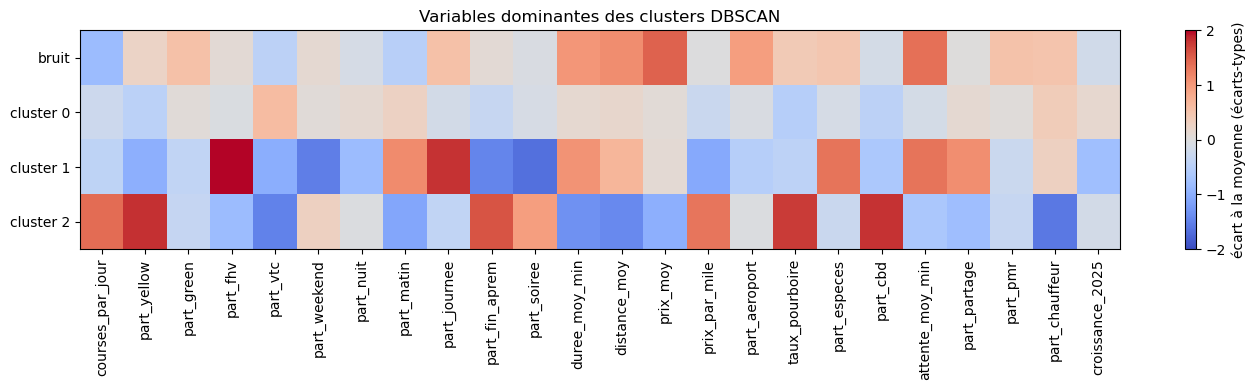

In [11]:
X_std = pd.read_csv(os.path.join(ML_DIR, "X_standardise.csv"))
FEATURES = list(X_std.columns)

ecarts_db = X_std.groupby(zones["cluster_dbscan"]).mean()
taille_db = zones["cluster_dbscan"].value_counts()

for c in ecarts_db.index:
    haut = ecarts_db.loc[c].sort_values(ascending=False).head(4)
    bas = ecarts_db.loc[c].sort_values().head(3)
    titre = "Bruit" if c == -1 else "Cluster " + str(c)
    majoritaire = zones.loc[zones["cluster_dbscan"] == c, "nom_segment_km"].value_counts()
    print("\n" + titre, "(" + str(taille_db[c]) + " zones) | segment K-Means majoritaire :",
          majoritaire.index[0], "(" + str(majoritaire.iloc[0]) + " zones)")
    print("  nettement AU-DESSUS :", ", ".join(v + " (+" + str(round(haut[v], 2)) + ")" for v in haut.index))
    print("  nettement EN DESSOUS :", ", ".join(v + " (" + str(round(bas[v], 2)) + ")" for v in bas.index))

plt.figure(figsize=(14, 4))
plt.imshow(ecarts_db, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
plt.colorbar(label="écart à la moyenne (écarts-types)")
plt.xticks(range(len(FEATURES)), FEATURES, rotation=90)
plt.yticks(range(len(ecarts_db)), ["bruit" if c == -1 else "cluster " + str(c) for c in ecarts_db.index])
plt.title("Variables dominantes des clusters DBSCAN")
plt.tight_layout()
plt.show()

In [12]:
NOMS_DBSCAN = {
    -1: "Zones atypiques (bruit)",
    0: "VTC en banlieue",
    1: "Banlieue FHV",
    2: "Manhattan taxi",
}

zones["nom_segment_dbscan"] = zones["cluster_dbscan"].map(NOMS_DBSCAN).fillna("À NOMMER")
display(zones.groupby(["cluster_dbscan", "nom_segment_dbscan"]).size().to_frame("nb_zones"))

,,nb_zones
cluster_dbscan,nom_segment_dbscan,
-1,Zones atypiques (bruit),24
0,VTC en banlieue,167
1,Banlieue FHV,17
2,Manhattan taxi,49


In [13]:
segments = pd.read_csv(os.path.join(ML_DIR, "zones_segments.csv"))
segments = segments.drop(columns=["cluster_dbscan", "nom_segment_dbscan"], errors="ignore")
segments = segments.merge(zones[["zone_id", "cluster_dbscan", "nom_segment_dbscan"]], on="zone_id", how="left")
segments["cluster_dbscan"] = segments["cluster_dbscan"].fillna(-2).astype(int)
segments["nom_segment_dbscan"] = segments["nom_segment_dbscan"].fillna("Faible activité (non segmentée)")

cible = os.path.join(ML_DIR, "zones_segments.csv")
segments.to_csv(cible, index=False)
print("Sauvegardé :", cible, "| lignes :", segments.shape[0], "| colonnes :", segments.shape[1])
display(pd.crosstab(segments["nom_segment_km"], segments["nom_segment_dbscan"]))
display(segments[["zone_id", "nom_zone", "segment_km", "nom_segment_km", "cluster_dbscan", "nom_segment_dbscan"]].head(10))

Sauvegardé : c:\Users\DELL\Desktop\esprit\ML\notebook_v0\Nootebook_vf\ml_data\zones_segments.csv | lignes : 263 | colonnes : 33


nom_segment_dbscan,Banlieue FHV,Faible activité (non segmentée),Manhattan taxi,VTC en banlieue,Zones atypiques (bruit)
nom_segment_km,,,,,
Aéroports et longs trajets,0,0,0,1,12
Banlieue FHV,17,0,0,3,4
Faible activité (non segmentée),0,6,0,0,0
Manhattan taxi,0,0,48,1,1
Quartiers de sortie,0,0,1,44,5
Résidentiel VTC,0,0,0,118,2


,zone_id,nom_zone,segment_km,nom_segment_km,cluster_dbscan,nom_segment_dbscan
0,1,Newark Airport,3,Aéroports et longs trajets,-1,Zones atypiques (bruit)
1,2,Jamaica Bay,-1,Faible activité (non segmentée),-2,Faible activité (non segmentée)
2,3,Allerton/Pelham Gardens,1,Résidentiel VTC,0,VTC en banlieue
3,4,Alphabet City,0,Quartiers de sortie,-1,Zones atypiques (bruit)
4,5,Arden Heights,4,Banlieue FHV,1,Banlieue FHV
5,6,Arrochar/Fort Wadsworth,4,Banlieue FHV,1,Banlieue FHV
6,7,Astoria,0,Quartiers de sortie,0,VTC en banlieue
7,8,Astoria Park,0,Quartiers de sortie,0,VTC en banlieue
8,9,Auburndale,1,Résidentiel VTC,0,VTC en banlieue
9,10,Baisley Park,1,Résidentiel VTC,0,VTC en banlieue
